# Procesamiento de señales · Filtros y aplicaciones

Continuación de *Muestreo y espectro*. Se programa la **convolución** a mano y por FFT, y se aplican filtros a señales sintéticas con ruido: media móvil, Butterworth paso bajo y paso alto (`signal.butter` y `signal.filtfilt`) y un filtro *notch* para quitar el zumbido de la red eléctrica, midiendo su respuesta en frecuencia con `signal.freqz`. Después, tres aplicaciones: la **correlación cruzada** para estimar un retardo, el **espectrograma** de un *chirp* y la detección de los tonos del teclado telefónico (DTMF) con el **algoritmo de Goertzel**, guardando el audio en un WAV con el módulo `wave`. Ideas de [Think DSP](https://greenteapress.com/wp/think-dsp/) y de la [guía de `scipy.signal`](https://docs.scipy.org/doc/scipy/tutorial/signal.html).

In [1]:
import wave
from collections import Counter
from itertools import product

import matplotlib.pyplot as plt
import numpy as np
from scipy import signal


def espectro(x, fs):
    frecuencias = np.fft.rfftfreq(len(x), d=1 / fs)
    amplitudes = 2 * np.abs(np.fft.rfft(x)) / len(x)
    amplitudes[0] /= 2
    return frecuencias, amplitudes

## 1. Convolución a mano

Escribir la convolución discreta $(x * h)_n = \sum_k x_k\, h_{n-k}$ con dos bucles y usarla para obtener la distribución de la suma de dos y de tres dados, comparándola con el recuento de todas las tiradas posibles. Comprobar también los modos `"full"`, `"same"` y `"valid"` de `np.convolve`.

In [2]:
def convolucion(x, h):
    y = [0.0] * (len(x) + len(h) - 1)
    for i, xi in enumerate(x):
        for j, hj in enumerate(h):
            y[i + j] += xi * hj
    return np.array(y)


dado = np.full(6, 1 / 6)
dos = convolucion(dado, dado)
tres = convolucion(dos, dado)
for caras, dist in [(2, dos), (3, tres)]:
    cuenta = Counter(map(sum, product(range(1, 7), repeat=caras)))
    esperado = np.array([cuenta[s] for s in range(caras, 6 * caras + 1)]) / 6 ** caras
    assert np.allclose(dist, esperado)
print("Suma de dos dados:", " ".join(f"{s}:{p * 36:.0f}/36" for s, p in zip(range(2, 13), dos)))

rng = np.random.default_rng(0)
x, h = rng.normal(size=20), rng.normal(size=5)
completa = convolucion(x, h)
assert np.allclose(completa, np.convolve(x, h))
assert np.allclose(completa[2:-2], np.convolve(x, h, mode="same"))
assert np.allclose(completa[4:-4], np.convolve(x, h, mode="valid"))
print("Longitudes full, same, valid:", [len(np.convolve(x, h, mode=m)) for m in ["full", "same", "valid"]])

Suma de dos dados: 2:1/36 3:2/36 4:3/36 5:4/36 6:5/36 7:6/36 8:5/36 9:4/36 10:3/36 11:2/36 12:1/36
Longitudes full, same, valid: [24, 20, 16]


## 2. Convolución por FFT

La convolución en el tiempo es un producto en frecuencia. Calcularla multiplicando las `rfft` de las dos señales rellenadas con ceros hasta $N + M - 1$ y comparar con `np.convolve` y `signal.fftconvolve`. Sin el relleno, el producto da la convolución **circular**: comprobarlo con su definición $\sum_k h_k\, x_{(n-k) \bmod N}$.

In [3]:
def convolucion_fft(x, h):
    n = len(x) + len(h) - 1
    return np.fft.irfft(np.fft.rfft(x, n) * np.fft.rfft(h, n), n)


x, h = rng.normal(size=1000), rng.normal(size=51)
lineal = convolucion_fft(x, h)
assert np.allclose(lineal, np.convolve(x, h)) and np.allclose(lineal, signal.fftconvolve(x, h))

N = len(x)
circular = np.fft.irfft(np.fft.rfft(x) * np.fft.rfft(h, N), N)
definicion = np.array([sum(h[k] * x[(n - k) % N] for k in range(len(h))) for n in range(N)])
assert np.allclose(circular, definicion)
diferentes = np.flatnonzero(~np.isclose(circular, lineal[:N]))
print(f"La circular difiere de la lineal en las muestras {diferentes.min()}..{diferentes.max()}")
assert list(diferentes) == list(range(len(h) - 1))

La circular difiere de la lineal en las muestras 0..49


## 3. Media móvil

Suavizar con una media móvil de $M$ muestras (convolución con `np.ones(M) / M`). Comprobar que, aplicada a ruido blanco, divide su desviación por $\sqrt{M}$, y que su respuesta en frecuencia (`signal.freqz`) se anula en los múltiplos de $f_s / M$, de modo que elimina por completo los tonos de esas frecuencias.

In [4]:
fs = 1000
ruido = rng.normal(size=100_000)
for M in [4, 10, 25]:
    suavizado = np.convolve(ruido, np.ones(M) / M, mode="valid")
    print(f"M = {M:2}: desviación {suavizado.std():.4f}; 1/√M = {1 / np.sqrt(M):.4f}")
    assert abs(suavizado.std() * np.sqrt(M) - 1) < 0.02

M = 10
f, H = signal.freqz(np.ones(M) / M, worN=np.arange(0, 501, 50), fs=fs)
for fi, hi in zip(f, np.abs(H)):
    print(f"{fi:5.0f} Hz  |H| = {hi:.3f}")
assert np.allclose(np.abs(H[2::2]), 0, atol=1e-12)

t = np.arange(fs) / fs
tono = np.sin(2 * np.pi * 200 * t)
assert np.allclose(np.convolve(tono, np.ones(M) / M, mode="valid"), 0, atol=1e-12)

M =  4: desviación 0.5001; 1/√M = 0.5000
M = 10: desviación 0.3155; 1/√M = 0.3162
M = 25: desviación 0.2002; 1/√M = 0.2000
    0 Hz  |H| = 1.000
   50 Hz  |H| = 0.639
  100 Hz  |H| = 0.000
  150 Hz  |H| = 0.220
  200 Hz  |H| = 0.000
  250 Hz  |H| = 0.141
  300 Hz  |H| = 0.000
  350 Hz  |H| = 0.112
  400 Hz  |H| = 0.000
  450 Hz  |H| = 0.101
  500 Hz  |H| = 0.000


## 4. Filtro paso bajo Butterworth

Una señal útil con componentes de 5 y 12 Hz llega con ruido blanco y una interferencia de 130 Hz. Diseñar un Butterworth paso bajo de orden 4 con corte en 25 Hz (`signal.butter`), aplicarlo con `signal.filtfilt` y comparar el error con la señal limpia antes y después del filtro, y con una media móvil de 20 muestras (que además atenúa un 9 % el tono de 12 Hz). Dibujar un tramo.

sin filtrar  error RMS: 0.596
media móvil  error RMS: 0.123
Butterworth  error RMS: 0.131


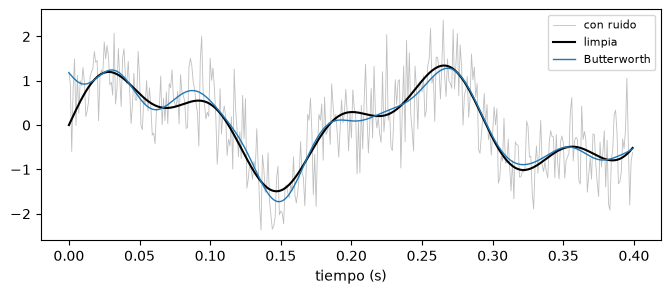

In [5]:
limpia = np.sin(2 * np.pi * 5 * t) + 0.5 * np.sin(2 * np.pi * 12 * t)
sucia = limpia + rng.normal(0, 0.5, t.size) + 0.4 * np.sin(2 * np.pi * 130 * t)
b, a = signal.butter(4, 25, btype="lowpass", fs=fs)
filtrada = signal.filtfilt(b, a, sucia)
media = np.convolve(sucia, np.ones(20) / 20, mode="same")


def rmse(x, y):
    return np.sqrt(np.mean((x - y) ** 2))


for nombre, y in [("sin filtrar", sucia), ("media móvil", media), ("Butterworth", filtrada)]:
    print(f"{nombre:12} error RMS: {rmse(y, limpia):.3f}")
assert max(rmse(filtrada, limpia), rmse(media, limpia)) < rmse(sucia, limpia) / 3

fig, ax = plt.subplots(figsize=(8, 3))
tramo = slice(0, 400)
ax.plot(t[tramo], sucia[tramo], color="0.75", lw=0.6, label="con ruido")
ax.plot(t[tramo], limpia[tramo], "k", lw=1.5, label="limpia")
ax.plot(t[tramo], filtrada[tramo], lw=1, label="Butterworth")
ax.set(xlabel="tiempo (s)")
ax.legend(fontsize=8)
plt.show()

## 5. Respuesta en frecuencia del Butterworth

Calcular con `signal.freqz` la ganancia en dB de filtros Butterworth paso bajo de órdenes 2, 4 y 6 con corte en 10 Hz. Comprobar que en la frecuencia de corte la ganancia es $-3{,}01$ dB sea cual sea el orden y que una década más arriba (100 Hz) cae unos $20n$ dB. Dibujar las tres curvas en escala logarítmica.

orden 2:  -3.01 dB a 10 Hz,  -40.58 dB a 100 Hz
orden 4:  -3.01 dB a 10 Hz,  -81.16 dB a 100 Hz
orden 6:  -3.01 dB a 10 Hz, -121.74 dB a 100 Hz


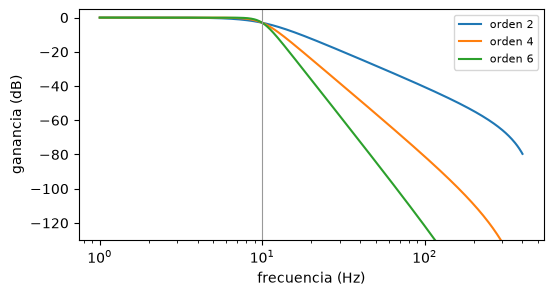

In [6]:
frecuencias = np.logspace(0, np.log10(400), 400)
fig, ax = plt.subplots(figsize=(6, 3))
for orden in [2, 4, 6]:
    b, a = signal.butter(orden, 10, fs=fs)
    _, H = signal.freqz(b, a, worN=np.r_[10, 100, frecuencias], fs=fs)
    db = 20 * np.log10(np.abs(H))
    print(f"orden {orden}: {db[0]:6.2f} dB a 10 Hz, {db[1]:7.2f} dB a 100 Hz")
    assert np.isclose(db[0], -3.01, atol=0.01) and abs(db[1] + 20 * orden) < orden
    ax.semilogx(frecuencias, db[2:], label=f"orden {orden}")
ax.set(ylim=(-130, 5), xlabel="frecuencia (Hz)", ylabel="ganancia (dB)")
ax.axvline(10, color="0.6", lw=0.8)
ax.legend(fontsize=8)
plt.show()

## 6. Filtro paso alto para quitar la deriva

Un sensor mide un tono de 10 Hz montado sobre una deriva lenta (una rampa y una oscilación de 0,1 Hz). Quitar la deriva con un Butterworth paso alto de orden 2 y corte en 2 Hz, aplicado con `filtfilt`, y comprobar que en el tramo central la señal recuperada se parece al tono y tiene media casi nula.

Media antes: 2.500; después: 0.0000
Error máximo en el tramo central: 0.0017


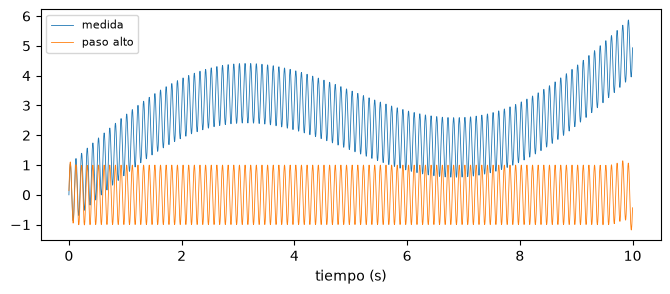

In [7]:
t10 = np.arange(10 * fs) / fs
tono = np.sin(2 * np.pi * 10 * t10)
deriva = 0.5 * t10 + 2 * np.sin(2 * np.pi * 0.1 * t10)
b, a = signal.butter(2, 2, btype="highpass", fs=fs)
recuperado = signal.filtfilt(b, a, tono + deriva)
centro = slice(fs, 9 * fs)
print(f"Media antes: {np.mean(tono + deriva):.3f}; después: {np.mean(recuperado[centro]):.4f}")
print(f"Error máximo en el tramo central: {np.max(np.abs(recuperado[centro] - tono[centro])):.4f}")
assert abs(np.mean(recuperado[centro])) < 0.01 and np.max(np.abs(recuperado[centro] - tono[centro])) < 0.1

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(t10, tono + deriva, lw=0.6, label="medida")
ax.plot(t10, recuperado, lw=0.6, label="paso alto")
ax.set(xlabel="tiempo (s)")
ax.legend(fontsize=8)
plt.show()

## 7. Quitar el zumbido de 50 Hz con un *notch*

Una grabación de un tono de 10 Hz tiene un zumbido de la red eléctrica de 50 Hz. Diseñar un filtro de banda eliminada estrecho con `signal.iirnotch` (factor de calidad 30), aplicarlo y comprobar en el espectro que el zumbido baja más de 40 dB mientras el tono útil conserva su amplitud.

In [8]:
x = np.sin(2 * np.pi * 10 * t10) + 0.8 * np.sin(2 * np.pi * 50 * t10)
b, a = signal.iirnotch(50, Q=30, fs=fs)
y = signal.filtfilt(b, a, x)
f, antes = espectro(x, fs)
_, despues = espectro(y, fs)
for f0 in [10, 50]:
    i = np.searchsorted(f, f0)
    print(f"{f0} Hz: {antes[i]:.3f} -> {despues[i]:.5f} ({20 * np.log10(despues[i] / antes[i]):7.2f} dB)")
i10, i50 = np.searchsorted(f, [10, 50])
assert 20 * np.log10(despues[i50] / antes[i50]) < -40 and abs(despues[i10] - 1) < 0.01

10 Hz: 1.000 -> 0.99995 (  -0.00 dB)
50 Hz: 0.800 -> 0.00741 ( -40.67 dB)


## 8. Correlación cruzada para estimar un retardo

Dos micrófonos a distinta distancia de una fuente graban el mismo ruido, el segundo con 37 muestras de retraso a 48 kHz y con más ruido propio. Estimar el retardo con el máximo de la correlación cruzada (`signal.correlate` y `signal.correlation_lags`) y convertirlo en diferencia de distancias con una velocidad del sonido de 343 m/s. Comprobar que la correlación directa y la calculada por FFT coinciden.

Retardo estimado: 37 muestras = 0.771 ms -> 26.4 cm más lejos


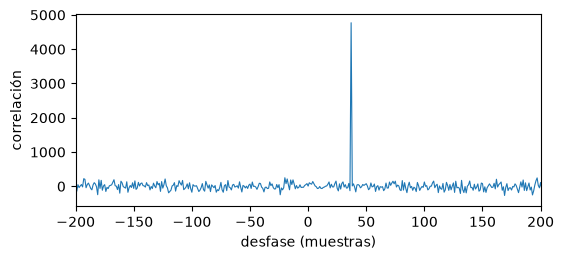

In [9]:
fs_audio, retardo = 48_000, 37
fuente = rng.normal(size=5000)
mic1 = fuente[retardo:] + rng.normal(0, 0.3, 5000 - retardo)
mic2 = fuente[:-retardo] + rng.normal(0, 0.8, 5000 - retardo)

correlacion = signal.correlate(mic2, mic1, method="direct")
desfases = signal.correlation_lags(len(mic2), len(mic1))
estimado = desfases[correlacion.argmax()]
print(f"Retardo estimado: {estimado} muestras = {estimado / fs_audio * 1000:.3f} ms "
      f"-> {estimado / fs_audio * 343 * 100:.1f} cm más lejos")
assert estimado == retardo
assert np.allclose(correlacion, signal.correlate(mic2, mic1, method="fft"))
assert np.allclose(correlacion, np.correlate(mic2, mic1, mode="full"))

fig, ax = plt.subplots(figsize=(6, 2.5))
ax.plot(desfases, correlacion, lw=0.8)
ax.set(xlim=(-200, 200), xlabel="desfase (muestras)", ylabel="correlación")
plt.show()

## 9. `lfilter` frente a `filtfilt`: el desfase

`signal.lfilter` aplica el filtro una vez hacia delante y retrasa la señal; `filtfilt` lo aplica hacia delante y hacia atrás y anula el desfase. Pasar un seno de 5 Hz por un Butterworth paso bajo de orden 4 y 20 Hz con cada función y medir el retraso con la correlación cruzada, ignorando el transitorio inicial. Comparar el retraso de `lfilter` con la fase de `freqz` a 5 Hz.

In [10]:
seno = np.sin(2 * np.pi * 5 * t10)
b, a = signal.butter(4, 20, fs=fs)
estable = slice(fs, 9 * fs)


def retraso(salida, entrada):
    c = signal.correlate(salida[estable], entrada[estable])
    return signal.correlation_lags(len(salida[estable]), len(entrada[estable]))[c.argmax()]


r_lfilter = retraso(signal.lfilter(b, a, seno), seno)
r_filtfilt = retraso(signal.filtfilt(b, a, seno), seno)
_, H = signal.freqz(b, a, worN=[5], fs=fs)
teorico = -np.angle(H[0]) / (2 * np.pi * 5) * fs
print(f"Retraso con lfilter: {r_lfilter} muestras (fase a 5 Hz: {teorico:.1f}); con filtfilt: {r_filtfilt}")
assert r_filtfilt == 0 and abs(r_lfilter - teorico) <= 1

Retraso con lfilter: 21 muestras (fase a 5 Hz: 21.0); con filtfilt: 0


## 10. Espectrograma de un *chirp*

Generar un *chirp* lineal de 2 s que sube de 50 a 600 Hz (`signal.chirp`) muestreado a 2000 Hz y calcular su espectrograma con `signal.spectrogram` (segmentos de 256 muestras con solapamiento de 192). Comprobar que, en cada instante, la frecuencia con más potencia sigue la ley $f(t) = f_0 + (f_1 - f_0)\, t / T$ con un error menor que dos veces la resolución $f_s / 256$.

59 instantes; resolución 7.81 Hz; error máximo 3.74 Hz


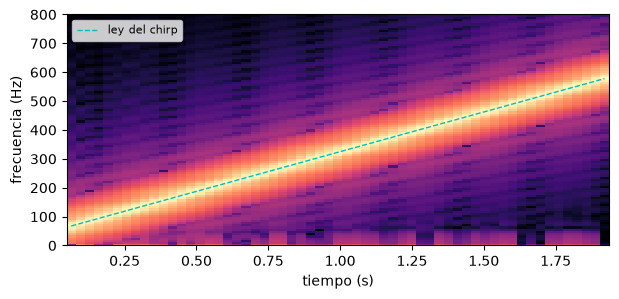

In [11]:
fs_c, T, f0, f1 = 2000, 2.0, 50, 600
tc = np.arange(int(fs_c * T)) / fs_c
chirp = signal.chirp(tc, f0=f0, t1=T, f1=f1, method="linear")
f, tiempos, S = signal.spectrogram(chirp, fs=fs_c, nperseg=256, noverlap=192)
dominante = f[S.argmax(axis=0)]
esperada = f0 + (f1 - f0) * tiempos / T
resolucion = fs_c / 256
print(f"{len(tiempos)} instantes; resolución {resolucion:.2f} Hz; error máximo {np.max(np.abs(dominante - esperada)):.2f} Hz")
assert np.all(np.abs(dominante - esperada) < 2 * resolucion)

fig, ax = plt.subplots(figsize=(7, 3))
ax.pcolormesh(tiempos, f, 10 * np.log10(S + 1e-12), shading="auto", cmap="magma")
ax.plot(tiempos, esperada, "c--", lw=1, label="ley del chirp")
ax.set(ylim=(0, 800), xlabel="tiempo (s)", ylabel="frecuencia (Hz)")
ax.legend(fontsize=8, loc="upper left")
plt.show()

## 11. Algoritmo de Goertzel

Cuando solo interesan unas pocas frecuencias, el algoritmo de Goertzel calcula la potencia de una sola componente de la DFT con una recursión de segundo orden y una multiplicación real por muestra, sin calcular la FFT completa. Programarlo y comprobar que coincide con $|X_k|^2$ de `np.fft.fft` en varias frecuencias de una señal aleatoria.

In [12]:
def goertzel(x, frecuencia, fs):
    """Potencia |X_k|² en k = frecuencia · N / fs (k puede no ser entero)."""
    w = 2 * np.pi * frecuencia / fs
    coef = 2 * np.cos(w)
    s1 = s2 = 0.0
    for muestra in x:
        s1, s2 = muestra + coef * s1 - s2, s1
    return s1 * s1 + s2 * s2 - coef * s1 * s2


x = rng.normal(size=205)
X = np.fft.fft(x)
for k in [0, 1, 18, 50, 102]:
    p = goertzel(x, k * 8000 / 205, 8000)
    print(f"k = {k:3}: Goertzel {p:10.3f}   |X_k|² {abs(X[k]) ** 2:10.3f}")
    assert np.isclose(p, abs(X[k]) ** 2)

k =   0: Goertzel    483.708   |X_k|²    483.708
k =   1: Goertzel     26.303   |X_k|²     26.303
k =  18: Goertzel     54.387   |X_k|²     54.387
k =  50: Goertzel     81.265   |X_k|²     81.265
k = 102: Goertzel    109.108   |X_k|²    109.108


## 12. Generar tonos DTMF y guardarlos en WAV

Cada tecla del teléfono suena como la suma de dos tonos: uno de fila (697, 770, 852 o 941 Hz) y otro de columna (1209, 1336, 1477 o 1633 Hz). Generar a 8000 Hz la secuencia de las 16 teclas, con 80 ms de tono y 50 ms de silencio entre teclas, y guardarla como `dtmf.wav` (16 bits, mono) junto al notebook con el módulo `wave`. Leer el fichero y comprobar que las muestras coinciden salvo el error de cuantificación.

In [13]:
FILAS = [697, 770, 852, 941]
COLUMNAS = [1209, 1336, 1477, 1633]
TECLADO = ["123A", "456B", "789C", "*0#D"]
FS_TEL = 8000


def dtmf(teclas, tono=0.08, silencio=0.05, fs=FS_TEL):
    n = np.arange(int(tono * fs)) / fs
    partes = []
    for tecla in teclas:
        fila = next(i for i, f in enumerate(TECLADO) if tecla in f)
        columna = TECLADO[fila].index(tecla)
        partes += [0.45 * (np.sin(2 * np.pi * FILAS[fila] * n) + np.sin(2 * np.pi * COLUMNAS[columna] * n)),
                   np.zeros(int(silencio * fs))]
    return np.concatenate(partes)


teclas = "".join(TECLADO)
audio = dtmf(teclas)
with wave.open("dtmf.wav", "wb") as w:
    w.setnchannels(1)
    w.setsampwidth(2)
    w.setframerate(FS_TEL)
    w.writeframes(np.round(audio * 32767).astype("<i2").tobytes())

with wave.open("dtmf.wav", "rb") as w:
    print(f"Canales: {w.getnchannels()}, bytes por muestra: {w.getsampwidth()}, "
          f"frecuencia: {w.getframerate()} Hz, duración: {w.getnframes() / w.getframerate():.2f} s")
    leido = np.frombuffer(w.readframes(w.getnframes()), dtype="<i2") / 32767
assert len(leido) == len(audio) and np.max(np.abs(leido - audio)) <= 0.5 / 32767 + 1e-12

f, A = espectro(audio[:640], FS_TEL)
picos, _ = signal.find_peaks(A, height=0.2)
print("Picos de la tecla 1:", f[picos], "Hz")
assert len(picos) == 2 and np.all(np.abs(f[picos] - [697, 1209]) <= 12.5 / 2)  # bins de 12,5 Hz

Canales: 1, bytes por muestra: 2, frecuencia: 8000 Hz, duración: 2.08 s
Picos de la tecla 1: [ 700.  1212.5] Hz


## 13. Decodificar DTMF con Goertzel

Decodificar el audio anterior: dividirlo en bloques de 10 ms, marcar como activos los que tienen energía, agrupar los bloques activos consecutivos en pulsaciones y, en cada una, aplicar Goertzel a las ocho frecuencias DTMF para elegir la fila y la columna más fuertes. Comprobar que se recupera la secuencia original con el audio leído del WAV y también al añadirle ruido de varias intensidades.

In [14]:
def decodificar(x, fs=FS_TEL, bloque=80, umbral=0.15):
    energia = np.mean(x[:len(x) // bloque * bloque].reshape(-1, bloque) ** 2, axis=1)
    activos = energia > umbral
    teclas, inicio = [], None
    for i, activo in enumerate(np.append(activos, False)):
        if activo and inicio is None:
            inicio = i
        elif not activo and inicio is not None:
            trozo = x[inicio * bloque:i * bloque]
            fila = max(range(4), key=lambda k: goertzel(trozo, FILAS[k], fs))
            columna = max(range(4), key=lambda k: goertzel(trozo, COLUMNAS[k], fs))
            teclas.append(TECLADO[fila][columna])
            inicio = None
    return "".join(teclas)


print("Desde el WAV:", decodificar(leido))
assert decodificar(leido) == teclas
ruidoso = np.random.default_rng(7)
for sigma in [0.05, 0.2, 0.3]:
    mensaje = "928#0*13D"
    resultado = decodificar(dtmf(mensaje) + ruidoso.normal(0, sigma, len(dtmf(mensaje))))
    print(f"σ = {sigma}: {resultado}")
    assert resultado == mensaje

Desde el WAV: 123A456B789C*0#D
σ = 0.05: 928#0*13D
σ = 0.2: 928#0*13D
σ = 0.3: 928#0*13D
